# Notebook 04 — Modèles Satellites Macro
## Relation Macro → PD et Macro → LGD

**Objectif :** Établir les fonctions de sensibilité qui relient les variables macroéconomiques
au taux de défaut et à la LGD. Comparaison de 4 modèles (OLS / Ridge / LASSO / Probit)
avec métriques professionnelles. Calibration sur la crise 2008.

| Métrique | Seuil | Signification |
|---|---|---|
| R² ajusté | > 0.60 | Variance expliquée |
| RMSE | < 1pp | Erreur en points de taux de défaut |
| AIC / BIC | Minimiser | Parcimonie du modèle |
| Durbin-Watson | 1.5 – 2.5 | Absence d'autocorrélation des résidus |
| VIF | < 5 | Absence de multicolinéarité |


## Positionnement bancaire du notebook

**Role dans la plateforme**  
Relier cycle economique et risque credit: chomage, PIB, taux, spreads, inflation et delinquence.

**Lecture expert bancaire**  
Le stress testing bancaire doit expliquer comment un choc macro devient une hausse de PD/LGD/EAD.

**Sorties attendues**  
satellite_pd_comparison.csv, satellite_pd_walk_forward.csv, variables macro validees.

**Transition logique**  
Le notebook 05 applique des scenarios de choc cohérents aux parametres de risque.

In [1]:
import sys
sys.path.insert(0, '..')

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from pathlib import Path

plt.rcParams['figure.figsize'] = (12, 5)
sns.set_style('whitegrid')

OUTPUT_DIR = Path('../outputs')
RESULTS_DIR = OUTPUT_DIR / 'results'
RESULTS_DIR.mkdir(exist_ok=True)
print('Imports OK')


Imports OK


---
## 1. Chargement et agrégation


In [2]:
from src.data_prep import load_macro_data
from src.satellite_models import compute_quarterly_default_rate, merge_macro_quarterly
import pyarrow.parquet as pq

# Chargement optimisé — colonnes sélectionnées uniquement
parquet_path = OUTPUT_DIR / 'loan_clean.parquet'
schema = pq.read_schema(parquet_path)
available = set(schema.names)

# Colonnes minimales pour quarterlisation
needed = ['default_flag', 'issue_d', 'LGD', 'EAD']
cols = [c for c in needed if c in available]

df = pd.read_parquet(parquet_path, columns=cols)
print(f'Dataset chargé (colonnes minimales) : {df.shape}')

macro = load_macro_data()

# Agrégation trimestrielle du taux de défaut
dr_quarterly = compute_quarterly_default_rate(df)

# Fusion avec macro
data = merge_macro_quarterly(dr_quarterly, macro)

print(f'\nDataset trimestriel : {data.shape}')
print(data[['DR', 'UNRATE', 'GDPC1_growth', 'FEDFUNDS', 'HY_SPREAD']].describe().round(3))


Dataset chargé (colonnes minimales) : (2260668, 4)
[load_macro_data] 315 points mensuels, colonnes : ['UNRATE', 'FEDFUNDS', 'CPI', 'GDPC1', 'GDP', 'DRCCLACBS', 'HY_SPREAD', 'GDPC1_growth', 'CPI_change']
[compute_quarterly_default_rate] 47 trimestres — DR range: 0.03% → 29.56%
  [merge_macro_quarterly] Cible DR recalibrée via DRCCLACBS (facteur ×4.25) → range 0.090-0.284
[merge_macro_quarterly] 47 observations | Prédicteurs disponibles : ['UNRATE', 'GDPC1_growth', 'FEDFUNDS', 'HY_SPREAD', 'CPI_change']

Dataset trimestriel : (47, 14)
           DR  UNRATE  GDPC1_growth  FEDFUNDS  HY_SPREAD
count  47.000  47.000        47.000    47.000     47.000
mean    0.145   6.562         1.749     0.831      6.006
std     0.060   2.010         1.664     1.307      3.044
min     0.090   3.767        -3.697     0.073      2.640
25%     0.101   4.850         1.621     0.118      4.064
50%     0.111   6.067         2.134     0.180      5.055
75%     0.189   8.267         2.583     1.052      6.529
max  

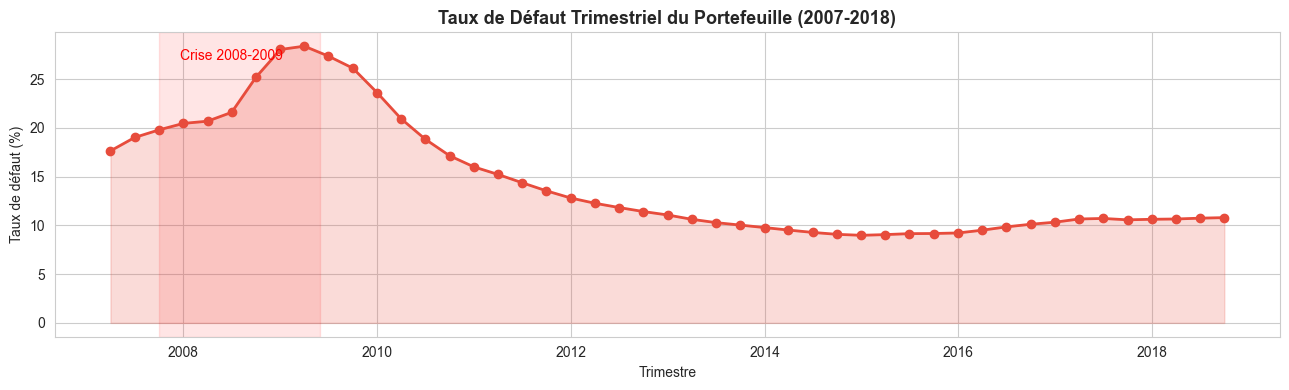

DR max (crise)  : 28.38% (2009-04-01 00:00:00)
DR min (normal) : 8.98%


In [3]:
# Visualisation du taux de défaut trimestriel
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(data.index, data['DR'] * 100, 'o-', color='#e74c3c', linewidth=2, markersize=6)
ax.fill_between(data.index, data['DR'] * 100, alpha=0.2, color='#e74c3c')
ax.axvspan(pd.Timestamp('2007-10'), pd.Timestamp('2009-06'), alpha=0.1, color='red')
ax.set_title('Taux de Défaut Trimestriel du Portefeuille (2007-2018)', fontweight='bold', fontsize=13)
ax.set_ylabel('Taux de défaut (%)')
ax.set_xlabel('Trimestre')
ax.annotate('Crise 2008-2009', xy=(pd.Timestamp('2008-07'), data['DR'].max()*100*0.95),
             fontsize=10, color='red', ha='center')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_20_dr_quarterly.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"DR max (crise)  : {data['DR'].max():.2%} ({data['DR'].idxmax()})")
print(f"DR min (normal) : {data['DR'].min():.2%}")


---
## 2. Analyse de multicolinéarité (VIF)


=== Variance Inflation Factor (VIF) ===
(VIF < 5 : OK | 5-10 : Attention | > 10 : Multicolinéarité sévère)
UNRATE          13.698251
HY_SPREAD        9.826450
CPI_change       4.226776
GDPC1_growth     3.260775
FEDFUNDS         2.076662


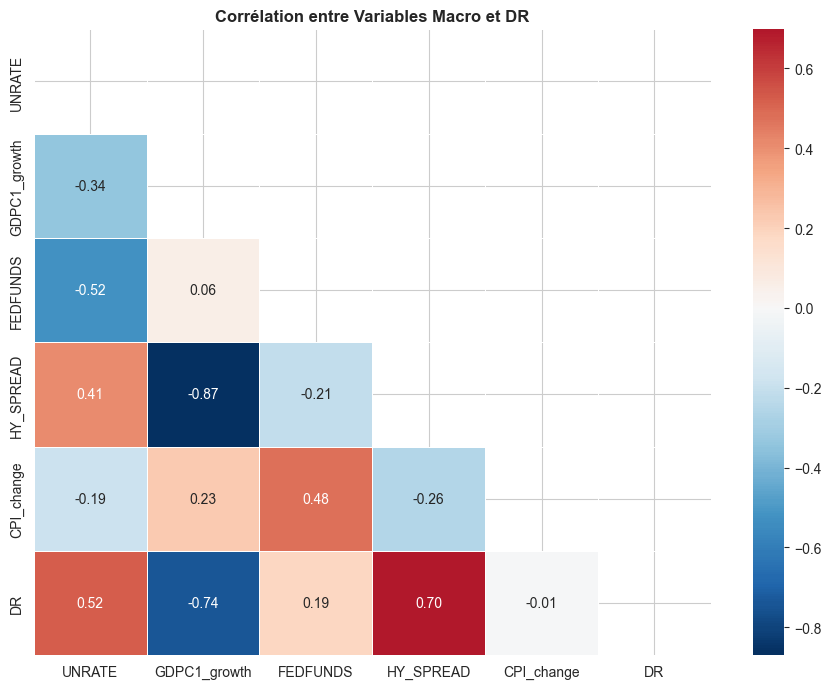

In [4]:
from src.satellite_models import compute_vif, MACRO_PD_VARS

macro_vars = [v for v in MACRO_PD_VARS if v in data.columns]
data_clean = data.dropna(subset=['DR'] + macro_vars)

vif = compute_vif(data_clean[macro_vars])
print('=== Variance Inflation Factor (VIF) ===')
print('(VIF < 5 : OK | 5-10 : Attention | > 10 : Multicolinéarité sévère)')
print(vif.sort_values(ascending=False).to_string())

# Heatmap de corrélation entre variables macro
plt.figure(figsize=(9, 7))
corr_macro = data_clean[macro_vars + ['DR']].corr()
mask = np.triu(np.ones_like(corr_macro, dtype=bool))
sns.heatmap(corr_macro, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            mask=mask, linewidths=0.5)
plt.title('Corrélation entre Variables Macro et DR', fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_21_macro_corr.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 3. Entraînement des 4 modèles Satellites PD


In [5]:
from src.satellite_models import train_satellite_pd

print('=== Entraînement des Modèles Satellites PD ===')
print('Train: 2007-2014 | Validation: 2015-2018\n')

sat_pd_models, sat_pd_results = train_satellite_pd(data, macro_vars, val_start='2015', save=True)


=== Entraînement des Modèles Satellites PD ===
Train: 2007-2014 | Validation: 2015-2018

  OLS      → R²_adj=-29.6069 | RMSE=0.0311 | DW=0.092 ✗ Problème autocorrélation
  Ridge    → R²_adj=-17.9050 | RMSE=0.0245 | DW=0.140
  LASSO    → R²_adj=-20.5208 | RMSE=0.0261 | 4/5 vars sélectionnées
  ElasticNet -> RMSE=0.0286
  RF-Reg   -> RMSE=0.0648
  GB-Reg   -> RMSE=0.0654
  XGB-Reg  -> RMSE=0.0656
  [WARN] Probit échoué : endog must be binary, either 0 or 1

✓ Modèle satellite PD champion : Ridge (RMSE=0.0245)


In [6]:
# Tableau comparatif
print('\n=== Tableau Comparatif — Modèles Satellites PD ===')

def style_satellite_table(df_metrics):
    try:
        from importlib.util import find_spec
        if find_spec('jinja2') is None:
            raise ImportError('jinja2 not available')

        higher_better = ['R²', 'R²_adj']
        lower_better  = ['RMSE', 'MAE', 'AIC', 'BIC']
        styled = df_metrics.style
        for col in higher_better:
            if col in df_metrics.columns:
                styled = styled.highlight_max(subset=[col], color='#90EE90')
        for col in lower_better:
            if col in df_metrics.columns:
                styled = styled.highlight_min(subset=[col], color='#90EE90')
        return styled
    except (ImportError, AttributeError):
        print(df_metrics.to_string())
        return None

styled_table = style_satellite_table(sat_pd_results)
if styled_table is not None:
    display(styled_table)

print('\nSeuils : R²_adj > 0.60 | RMSE < 0.01 | DW ∈ [1.5, 2.5]')



=== Tableau Comparatif — Modèles Satellites PD ===


,R²,R²_adj,RMSE,MAE,AIC,BIC,DW,DW_ok,DR_base_check,DR_shock_check,economic_ok,stress_lift_check
Model,,,,,,,,,,,,
OLS,-19.404600,-29.606900,0.031100,0.028000,-132.000000,-123.300000,0.092000,✗ Problème autocorrélation,0.106400,0.281300,True,2.642500
Ridge,-11.603400,-17.905000,0.024500,0.021200,nan,nan,0.140000,✗ Problème autocorrélation,0.111400,0.274500,True,2.464500
LASSO,-13.347200,-20.520800,0.026100,0.023000,nan,nan,0.123000,✗ Problème autocorrélation,0.109900,0.276300,True,2.514600
ElasticNet,-16.221900,-24.832800,0.028600,0.025500,nan,nan,0.105000,✗ Problème autocorrélation,0.108100,0.279000,True,2.580200
RandomForestReg,-87.382300,-131.573400,0.064800,0.060800,nan,nan,0.066000,✗ Problème autocorrélation,0.165300,0.216600,True,1.310200
GradientBoostingReg,-89.278300,-134.417400,0.065400,0.061400,nan,nan,0.069000,✗ Problème autocorrélation,0.162500,0.206000,True,1.267300
XGBoostReg,-89.772700,-135.159000,0.065600,0.060900,nan,nan,0.092000,✗ Problème autocorrélation,0.157400,0.213800,True,1.357900



Seuils : R²_adj > 0.60 | RMSE < 0.01 | DW ∈ [1.5, 2.5]


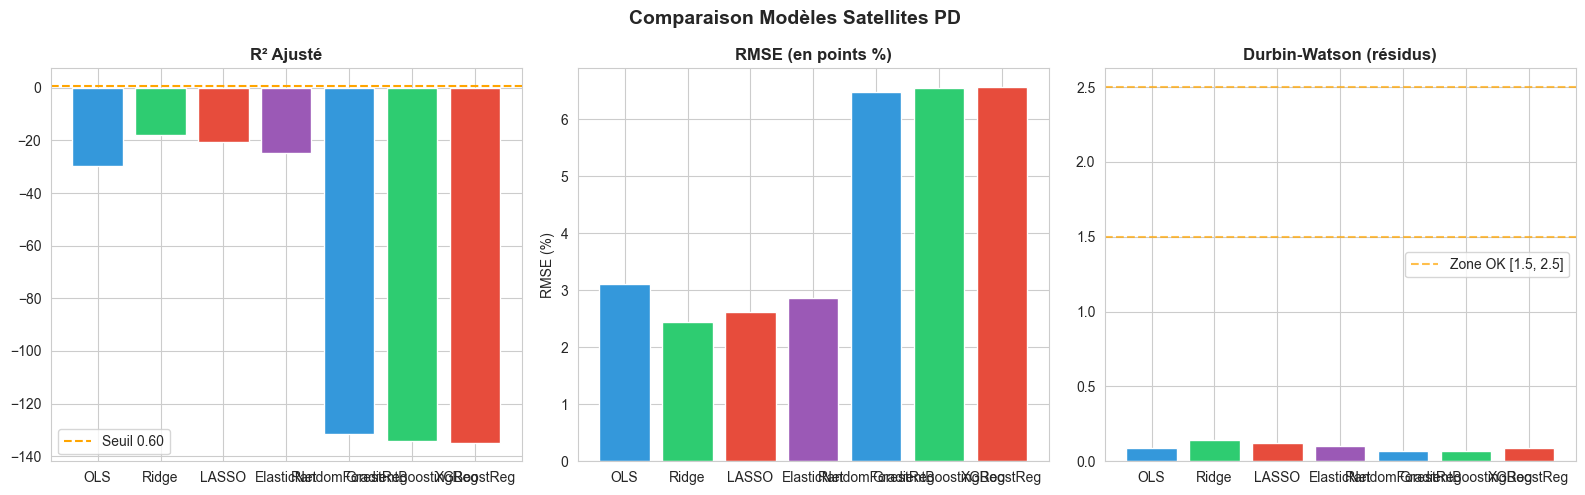

In [7]:
# Visualisation comparative
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

colors = ['#3498db', '#2ecc71', '#e74c3c', '#9b59b6']
models_sat = sat_pd_results.index.tolist()

# R² ajusté
axes[0].bar(models_sat, sat_pd_results['R²_adj'], color=colors[:len(models_sat)])
axes[0].axhline(0.60, color='orange', linestyle='--', label='Seuil 0.60')
axes[0].set_title('R² Ajusté', fontweight='bold')
axes[0].legend()

# RMSE
axes[1].bar(models_sat, sat_pd_results['RMSE'] * 100, color=colors[:len(models_sat)])
axes[1].set_title('RMSE (en points %)', fontweight='bold')
axes[1].set_ylabel('RMSE (%)')

# Durbin-Watson
axes[2].bar(models_sat, sat_pd_results['DW'], color=colors[:len(models_sat)])
axes[2].axhline(1.5, color='orange', linestyle='--', alpha=0.7)
axes[2].axhline(2.5, color='orange', linestyle='--', alpha=0.7, label='Zone OK [1.5, 2.5]')
axes[2].set_title('Durbin-Watson (résidus)', fontweight='bold')
axes[2].legend()

plt.suptitle('Comparaison Modèles Satellites PD', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_22_satellite_pd_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


---
## 4. Coefficients de sensibilité (modèle OLS)


=== Modèle OLS — Résultats Complets ===
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.848
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     27.93
Date:                Fri, 08 May 2026   Prob (F-statistic):           1.78e-09
Time:                        12:29:27   Log-Likelihood:                 71.976
No. Observations:                  31   AIC:                            -132.0
Df Residuals:                      25   BIC:                            -123.3
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       

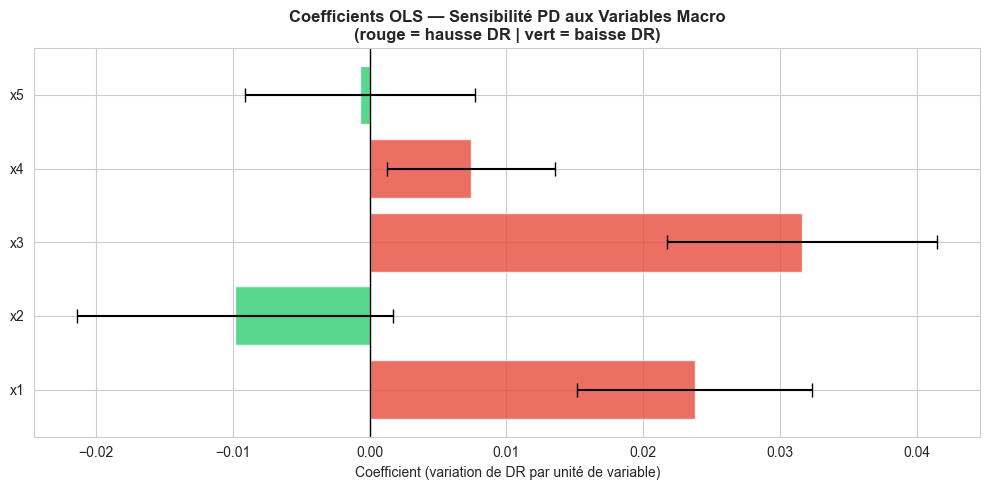


Significativité des variables :
  x1                   : p=0.0000  *** (1%)
  x2                   : p=0.0908  * (10%)
  x3                   : p=0.0000  *** (1%)
  x4                   : p=0.0204  ** (5%)
  x5                   : p=0.8702  NS


In [8]:
# Analyse du modèle OLS champion : coefficients + intervalles de confiance
if 'OLS' in sat_pd_models:
    ols_model = sat_pd_models['OLS']
    print('=== Modèle OLS — Résultats Complets ===')
    print(ols_model.summary())

    # Noms de variables explicatives pour aligner params / conf_int
    exog_names = getattr(getattr(ols_model, 'model', None), 'exog_names', None)

    # Params robustes (Series ou ndarray)
    params_raw = ols_model.params
    if isinstance(params_raw, pd.Series):
        params = params_raw
    else:
        if exog_names is None or len(exog_names) != len(params_raw):
            exog_names = [f'x{i}' for i in range(len(params_raw))]
        params = pd.Series(params_raw, index=exog_names)

    coefs = params.drop('const', errors='ignore')

    # Intervalles de confiance robustes (DataFrame ou ndarray)
    conf_raw = ols_model.conf_int()
    if isinstance(conf_raw, pd.DataFrame):
        conf_int = conf_raw
    else:
        conf_int = pd.DataFrame(conf_raw, index=params.index)
    conf_int = conf_int.drop('const', errors='ignore')

    # Graphe des coefficients
    fig, ax = plt.subplots(figsize=(10, 5))
    y_pos = range(len(coefs))
    colors_coef = ['#e74c3c' if v > 0 else '#2ecc71' for v in coefs]
    ax.barh(y_pos, coefs.values, color=colors_coef, alpha=0.8)
    ax.errorbar(
        coefs.values,
        y_pos,
        xerr=[coefs.values - conf_int[0].values, conf_int[1].values - coefs.values],
        fmt='none',
        color='black',
        capsize=5,
        linewidth=1.5,
    )
    ax.axvline(0, color='black', linewidth=1)
    ax.set_yticks(list(y_pos))
    ax.set_yticklabels(coefs.index)
    ax.set_title(
        'Coefficients OLS — Sensibilité PD aux Variables Macro\n(rouge = hausse DR | vert = baisse DR)',
        fontweight='bold',
    )
    ax.set_xlabel('Coefficient (variation de DR par unité de variable)')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fig_23_ols_coefficients.png', dpi=150, bbox_inches='tight')
    plt.show()

    # p-values robustes
    pvals_raw = getattr(ols_model, 'pvalues', None)
    if pvals_raw is not None:
        if isinstance(pvals_raw, pd.Series):
            pvals = pvals_raw
        else:
            pvals = pd.Series(pvals_raw, index=params.index)

        pvals = pvals.drop('const', errors='ignore')
        print('\nSignificativité des variables :')
        for var, pval in pvals.items():
            sig = '*** (1%)' if pval < 0.01 else '** (5%)' if pval < 0.05 else '* (10%)' if pval < 0.10 else 'NS'
            print(f'  {var:20s} : p={pval:.4f}  {sig}')
    else:
        print('\nP-values indisponibles pour cet estimateur OLS.')


---
## 5. Calibration sur la crise 2008


In [9]:
from src.satellite_models import calibrate_2008

champion_sat = sat_pd_results['RMSE'].idxmin()
print(f'Modèle champion satellite PD : {champion_sat}')


calib = calibrate_2008(data, sat_pd_models[champion_sat], champion_sat, macro_vars)


Modèle champion satellite PD : Ridge

=== Calibration Crise 2008-2009 ===
  Taux de défaut observé max  : 28.38% (2009-04-01 00:00:00)
  Taux de défaut prédit max   : 28.85%
  Écart                       : 0.48%


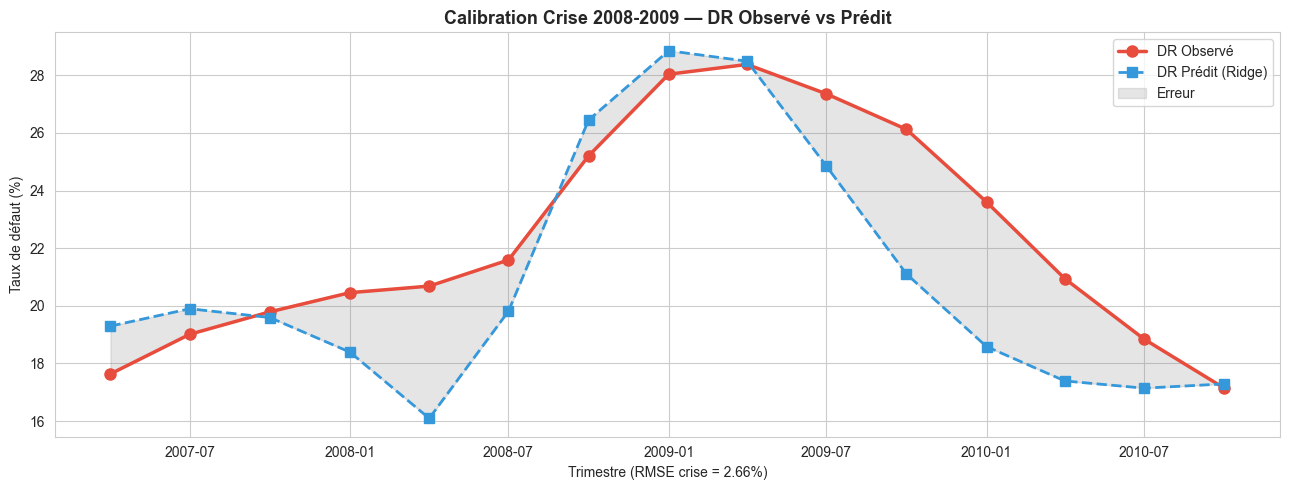

In [10]:
if calib.get('crisis_df') is not None:
    crisis_df = calib['crisis_df']
    
    fig, ax = plt.subplots(figsize=(13, 5))
    ax.plot(crisis_df.index, crisis_df['DR_observed'] * 100, 'o-',
            color='#e74c3c', linewidth=2.5, markersize=8, label='DR Observé')
    ax.plot(crisis_df.index, crisis_df['DR_predicted'] * 100, 's--',
            color='#3498db', linewidth=2, markersize=7, label=f'DR Prédit ({champion_sat})')
    ax.fill_between(crisis_df.index,
                     crisis_df['DR_observed'] * 100,
                     crisis_df['DR_predicted'] * 100,
                     alpha=0.2, color='gray', label='Erreur')
    ax.set_title('Calibration Crise 2008-2009 — DR Observé vs Prédit', fontweight='bold', fontsize=13)
    ax.set_ylabel('Taux de défaut (%)')
    ax.legend()
    
    rmse_crisis = np.sqrt(((crisis_df['DR_observed'] - crisis_df['DR_predicted'])**2).mean())
    ax.set_xlabel(f'Trimestre (RMSE crise = {rmse_crisis*100:.2f}%)')
    
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'fig_24_calibration_2008.png', dpi=150, bbox_inches='tight')
    plt.show()


---
## 6. Modèles Satellites LGD


In [11]:
from src.satellite_models import train_satellite_lgd

print('=== Modèles Satellites LGD ===')
sat_lgd_models, sat_lgd_results = train_satellite_lgd(data, val_start='2015', save=True)

if len(sat_lgd_results) > 0:
    print('\nRésultats satellites LGD :')
    display(style_satellite_table(sat_lgd_results))


=== Modèles Satellites LGD ===
  OLS    LGD → R²=-0.0599 | RMSE=0.0080
  Ridge  LGD → R²=-0.1135 | RMSE=0.0082
  LASSO  LGD → R²=-0.9999 | RMSE=0.0110

Résultats satellites LGD :


,R²,R²_adj,RMSE,MAE,AIC,BIC,DW,DW_ok
Model,,,,,,,,
OLS,-0.059900,-0.589900,0.008000,0.006900,-167.300000,-161.600000,0.326000,✗ Problème autocorrélation
Ridge,-0.113500,-0.670200,0.008200,0.006800,nan,nan,0.308000,✗ Problème autocorrélation
LASSO,-0.999900,-1.999800,0.011000,0.008500,nan,nan,0.168000,✗ Problème autocorrélation


---
## 7. Simulation satellite des scenarios macro

Cette etape ne calcule pas une ECL forward-looking. Elle verifie seulement comment le modele satellite transforme chaque scenario macro en taux de defaut stresse. Le vrai stress testing ECL est realise dans le notebook 05.


In [ ]:
from src.stress_scenarios import SCENARIOS, SCENARIO_LABELS, ACTIVE_STRESS_SCENARIOS
from src.satellite_models import predict_pd_satellite

# Pr?diction du taux de d?faut satellite pour chaque sc?nario macro.
# Objectif: pr?parer le lift PD du moteur de stress testing, pas pond?rer des sc?narios.
dr_rows = []
for sc_name, sc_vals in {"baseline": SCENARIOS["baseline"], **ACTIVE_STRESS_SCENARIOS}.items():
    dr = predict_pd_satellite(sc_vals, champion_sat, sat_pd_models, macro_vars)
    dr_rows.append({
        'scenario_key': sc_name,
        'scenario': SCENARIO_LABELS.get(sc_name, sc_name),
        'DR_satellite': dr,
        'lift_vs_baseline': dr / max(predict_pd_satellite(SCENARIOS['baseline'], champion_sat, sat_pd_models, macro_vars), 1e-6),
    })

scenario_dr = pd.DataFrame(dr_rows)
MODELS_DIR = OUTPUT_DIR / 'models'
MODELS_DIR.mkdir(exist_ok=True)
scenario_dr.to_csv(MODELS_DIR / 'satellite_scenario_dr.csv', index=False)
display(scenario_dr)

plt.figure(figsize=(10, 4))
plot_df = scenario_dr[scenario_dr['scenario_key'] != 'baseline']
plt.bar(plot_df['scenario'], plot_df['DR_satellite'] * 100, color='steelblue', edgecolor='white')
plt.axhline(scenario_dr.loc[scenario_dr['scenario_key'] == 'baseline', 'DR_satellite'].iloc[0] * 100,
            color='red', linestyle='--', label='Baseline')
plt.ylabel('DR satellite pr?dit (%)')
plt.title('R?action du mod?le satellite aux sc?narios macro', fontweight='bold')
plt.xticks(rotation=20, ha='right')
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig_25_satellite_scenario_dr.png', dpi=150, bbox_inches='tight')
plt.show()


## Coherence avec la chaine IFRS 9 + Bale + stress testing

Ce notebook s'inscrit dans la chaine complete:

`Donnees -> Qualite -> PD/LGD/EAD -> ECL IFRS 9 -> Satellites macro -> Stress Y1 -> RWA/CET1 -> Decision -> Gouvernance`

Les resultats finaux de niveau bancaire sont consolides dans:

- `notebooks/08_Banking_Expert_Review.ipynb`
- `outputs/results/one_year_stress_decision_matrix.csv`
- `outputs/results/basel_capital_metrics.csv`
- `outputs/results/regulatory_segment_summary.csv`
- `outputs/results/dynamic_projection_expert.csv`

Cette coherence permet de defendre le projet a la fois comme travail de modelisation
et comme prototype de plateforme bancaire.